# Clasificación de textos en esperanto: coches, aviones y trenes

**Minería de Textos · CUNEF · 2026/2027**

Eduardo Bernad Soria · Gonzalo Olivares · Pedro Riveiro

Clasificamos párrafos en esperanto en tres categorías cercanas: **coches** (*aŭtoj*), **aviones** (*aviadiloj*) y **trenes** (*trajnoj*). El cuaderno sigue las tres fases del enunciado:

| Sección | Contenido |
|---|---|
| 1 | Fase 1 · Dataset: descarga de Wikipedia, limpieza, exploración y ruido del etiquetado |
| 2 | Fase 2 · Modelo de NLP: tokenizador, etiquetador, lematizador, stop-words y objetos `Doc`/`Token` |
| 3 | Fase 3 · Vectorización (BoW y TF-IDF por clases) |
| 4 | Fase 3 · Entrenamiento y selección del modelo |
| 5 | Fase 3 · Evaluación: accuracy, F1 macro y matriz de confusión |
| 6 | Fase 3 · Clasificación de páginas web |
| 7 | Conclusiones |

El cuaderno es **autocontenido**: incluye el código que genera el dataset y todo el modelo de NLP. Además hemos hecho el **extra de arquitectura de software** (apartado 9.1): el mismo modelo de NLP está publicado como librería instalable con `pip` en nuestro repositorio [eduardobernad33/Mineria-de-textos](https://github.com/eduardobernad33/Mineria-de-textos), con tests, documentación y Pull Requests. En la sección 2.7 comprobamos que la librería y el código del cuaderno dan el mismo resultado.

**Ejecución:** en Google Colab, *Entorno de ejecución → Ejecutar todo*. No necesita GPU ni interacción y tarda menos de un minuto.

## 0. Configuración

Todos los resultados son reproducibles: la semilla está fijada, cada artículo de Wikipedia se descarga en una revisión fija y `VERSION` fija el commit de nuestro repositorio del que se cargan el dataset publicado, el léxico de la guía y la librería.

In [1]:
REPO = "eduardobernad33/Mineria-de-textos"
VERSION = "5ef9a6f3a11e3cab4c9d99e910ee237eae6f7e16"   # commit del repositorio: fija dataset, léxico y librería
GENERAR_DATASET = False     # True: vuelve a descargar Wikipedia y genera el dataset (unos 5 min)
SEMILLA = 42
TAMANO_VOCABULARIO = 1000   # nº de lemas del vocabulario (los más frecuentes del train)
PROPORCION_TEST = 0.2
CABECERAS = {"User-Agent": f"CUNEF-Vehiculos/1.0 (https://github.com/{REPO}) practica docente"}

In [2]:
import random
import re
import time
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import KFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

random.seed(SEMILLA)
np.random.seed(SEMILLA)
inicio = time.time()

CLASES = ["coches", "aviones", "trenes"]

## 1. Dataset (Fase 1)

Construimos el dataset con párrafos de 151 artículos de Wikipedia en esperanto. Cada párrafo recibe la clase de su artículo.

Como la descarga tarda unos minutos, por defecto se carga el CSV ya generado y publicado en nuestro repositorio (**ejecución asíncrona**, apartado 4.1.4). Con `GENERAR_DATASET = True` se ejecuta el código de esta sección y se vuelve a generar desde Wikipedia; si algún artículo falla (sin conexión, Wikipedia caída…), se usa la versión publicada.

### 1.1 Artículos de cada clase

Cada artículo va con el número de su **revisión** (`oldid`): así siempre se descarga el mismo texto aunque alguien edite el artículo después.

In [3]:
ARTICULOS = {
    "coches": {
        "Aŭto": 9505405, "Toyota Prius": 9362619, "Trabant": 9362627,
        "Elektra aŭtomobilo": 9408222, "Ford Modelo T": 8983603, "LADA Kalina": 9510800,
        "LADA 110": 9510799, "UAZ Patriot": 9452491, "Austin FX4": 9464588,
        "LADA Vesta": 8772806, "Chevrolet Viva": 8765158, "BS Nymph": 7944756,
        "Senŝofora aŭto": 8754591, "Tesla Model 3": 9254165, "Porsche 911": 9263712,
        "AMC Pacer": 9505445, "Chrysler Crossfire": 8770022, "Kombinaŭto": 9098716,
        "Koncepta aŭtomobilo": 8273925, "Volkswagen Tipo 1": 9329132, "Bugatti Veyron": 6095433,
        "Citroën DS": 8920599, "Citroën Traction Avant": 9401856,
        "Messerschmitt Kabinenroller": 8363736, "BMW Isetta": 7944743, "Goggomobil": 8208341,
        "Renault Clio": 8425740, "Benz Patent-Motorwagen": 9391564, "Kvarciklo Ford": 8972419,
        "Lancia Dilambda": 8312758, "Fiat 500": 8175285, "Renault 4": 9428890,
        "Citroën": 9364516,
    },
    "aviones": {
        "Aeroplano": 9419967, "Airbus A380": 9494683, "Concorde": 9473395, "Flyer 1": 9371993,
        "Supermarine Spitfire": 8930107, "Aviadilo": 9473384, "De Havilland Comet": 9493718,
        "Boeing 737": 8805074, "Boeing 777": 9263395, "Boeing 767": 9494682,
        "Boeing 707": 9494874, "Airbus A330": 8719032, "Airbus A300": 8785171,
        "Lockheed C-130 Hercules": 9118165, "General Dynamics F-16 Fighting Falcon": 9448264,
        "Boeing B-52 Stratofortress": 8856466, "North American P-51 Mustang": 9425695,
        "Lockheed Martin F-35 Lightning II": 9466633, "Lockheed Martin F-22 Raptor": 8330104,
        "Airbus A350 XWB": 9410816, "Bombaviadilo": 9175530, "Ĉasaviadilo": 8650686,
        "Militaviadilo": 9114551, "Ultramalpeza aviadilo": 8490419, "Biplano": 9360473,
        "Antonov An-124": 9146389, "Antonov An-225": 8873173, "Junkers Ju 52": 8933384,
        "McDonnell Douglas F-4 Phantom II": 8757602, "Messerschmitt Bf 109": 8363735,
        "Grumman F-14 Tomcat": 9065287, "Flugo Air France 447": 9435781,
        "Flugo 1549 de US Airways": 9435770, "Boeing": 9473361, "Airbus": 9473393,
        "Douglas DC-3": 8123220, "Boeing 747": 8450053, "Boeing 727": 6236153,
        "Boeing 787 Dreamliner": 8805075, "Airbus A340": 8718995, "Airbus A310": 8785172,
        "Airbus A318": 8748247, "Airbus A319": 9496119, "Airbus A321": 8718981,
        "McDonnell Douglas MD-11": 9494681, "Douglas DC-8": 9285675,
        "Lockheed L-1011 TriStar": 9473358, "Tupolev Tu-144": 8487662,
        "Komercaviadilo": 9473355, "Glisilo": 9089860, "Boeing B-17 Flying Fortress": 8461778,
        "Boeing B-29 Superfortress": 9419948, "McDonnell Douglas F-15 Eagle": 8429331,
        "Alerono": 9031506, "Fuzelaĝo": 9481613, "Tupolev ANT-9": 8487660,
        "Boeing 757": 9496120, "Boeing 717": 8719014, "Fokker 100": 8180465,
        "Messerschmitt Me 262": 8700457, "Iljuŝin Il-76": 8310601,
        "Lockheed P-38 Lightning": 9243777,
    },
    "trenes": {
        "Trajno": 9502151, "Lokomotivo": 9502150, "Vaporlokomotivo": 9479913, "TGV": 8962726,
        "Ŝinkanseno": 9335000, "Grandrapida trajno": 8641100, "Ŝvebotrajno": 9439323,
        "Orient-ekspreso": 8924242, "Dentorela fervojo": 8817898, "Eurostar": 8948537,
        "EuroCity": 8540992, "InterCityExpress": 8948521, "Intercités": 9325682,
        "Alta Velocidad Española": 9224890, "Railjet": 9168853, "Z 5300": 7888273,
        "Z 5600": 7888349, "Z 20500": 7888282, "MI 2N Altéo": 7888274, "MI 2N Eole": 8539010,
        "Z 20900": 7888346, "Z 50000": 9327595, "MI 09": 9422089, "RER NG": 8453574,
        "MF 01": 7256380, "MF 77": 9482366, "MF 88": 8340227, "MP 89": 8571160,
        "MP 51": 8444463, "MF 19": 9326174, "Bulgara ekspresa lokomotivo 1D1": 9432779,
        "Lokomotivo de la serio Ѵ": 9068935, "Serioj ER2 kaj ER9 de SZD": 8898663,
        "Pendolino de Fiat Ferroviaria": 8787993, "RegioJet": 9451435,
        "Vaporlokomotivriparejo de Meiningen": 9272139, "Trajneto de La Rhune": 9504499,
        "Fervojo Stockton kaj Darlington": 9298642, "Vaporlokomotivo 52 8055": 8788195,
        "Serio O de SZD": 8784186, "242 A1 de SNCF": 9504449, "Kuŝvagono": 8301386,
        "Kargotrajno": 9127361, "Talgo": 8618426, "Tramtrajno": 8568570, "Trajnunuo": 9115441,
        "Altrapida fervojo": 8663881, "Rodalies de Catalunya": 9314068,
        "Ŝinkansena linio Tōkaidō": 9438116, "Fervojo de Sóller": 9241319, "Vagono": 9302945,
        "Metroo sur pneŭoj": 9326137, "Dizellokomotivo": 9459576,
        "Deutsche Reichsbahn": 9338050, "DSB (Danske Statsbaner)": 9151934,
        "Nubotrajno": 8630978,
    },
}

print({clase: len(articulos) for clase, articulos in ARTICULOS.items()})

{'coches': 33, 'aviones': 62, 'trenes': 56}


### 1.2 Descarga y limpieza

- **Descarga** con la **API** de Wikipedia (tema 3.6): `action=parse` devuelve el HTML de la revisión pedida. Si Wikipedia pide esperar (error 429) o falla la conexión, se reintenta hasta 5 veces, y entre artículos hay una pausa de 1 s para no cargar el servidor.
- **Limpieza** con BeautifulSoup (tema 3.3): quitamos tablas, listas, fichas, imágenes y referencias, y saltamos secciones como *Referencoj* o *Eksteraj ligiloj*. De cada `<p>` quitamos las llamadas a notas `[1]` y los enlaces, cambiamos `;` por `,` (contrato de datos) y descartamos bloques de menos de 6 palabras.
- **Selección**, decidida revisando los resultados:
  - Los 15 primeros artículos los revisamos párrafo a párrafo y se guardan enteros. En *Elektra aŭtomobilo* quitamos los pasajes sobre trolebuses, furgonetas o carritos de golf, y en *Trajno* la sección de otros significados de la palabra.
  - En artículos generales (*Boeing*, *Airbus*, *RegioJet*…) solo guardamos los párrafos que nombran vehículos de su clase, y en *Aviadilo* solo los bloques sobre aviones.
  - Como máximo 32 párrafos por artículo (15 en *Flugo Air France 447*), elegidos con la semilla, para que ningún artículo pese demasiado.

In [4]:
API_WIKIPEDIA = "https://eo.wikipedia.org/w/api.php"

ETIQUETAS_RUIDO = ["table", "figure", "figcaption", "ul", "ol", "dl", "blockquote", "script", "style"]
CLASES_RUIDO = ["infobox", "navbox", "thumb", "hatnote", "ambox", "reflist", "mw-editsection",
                "mw-ref", "reference", "mw-cite-backlink", "mw-ext-cite-error"]
SECCIONES_OMITIDAS = {"bildaro", "bibliografio", "eksteraj ligiloj", "fontoj", "galerio",
                      "literaturo", "noto", "notoj", "referencoj", "vidu ankaŭ"}

# Casos especiales que decidimos revisando el resultado
ARTICULOS_REVISADOS = {"Aŭto", "Toyota Prius", "Trabant", "Elektra aŭtomobilo", "Ford Modelo T",
                       "Aeroplano", "Airbus A380", "Concorde", "Flyer 1", "Supermarine Spitfire",
                       "Trajno", "Lokomotivo", "Vaporlokomotivo", "TGV", "Ŝinkanseno"}
INICIOS_OMITIDOS = {
    "Elektra aŭtomobilo": ("La 29-an de aprilo de 1882", "1990-aj jaroj: EV1", "En 1975 aŭ 1976 surbaze",
                           "En 1980 oni ekpensis", "En 1983 sekvis kamioneto",
                           "En 1999 laŭ la mendo de golfo-klubo", "En 2002 surbaze de LADA Golf",
                           "En 2001-2002 la kompanio Bronto"),
}
GENERALES_TRENES = {"DSB (Danske Statsbaner)", "Deutsche Reichsbahn", "RegioJet",
                    "Rodalies de Catalunya", "Ŝinkansena linio Tōkaidō"}
GENERALES_AVIONES = {"Airbus", "Boeing", "Flugo 1549 de US Airways", "Flugo Air France 447"}
TERMINOS_TREN = r"trajn|lokomotiv|vagon|ŝinkansen|tgv|materialo rul"
TERMINOS_AVION = r"aviadil|aeroplan|flugil|jetmotor|pilotaŭtomat|boeing\s+\d|airbus\s+a\d"


def pedir_a_la_api(parametros):
    # Hasta 5 intentos: si Wikipedia pide esperar (429) o falla la conexión, esperamos y repetimos
    for intento in range(1, 6):
        try:
            respuesta = requests.get(API_WIKIPEDIA, params=parametros, headers=CABECERAS, timeout=30)
            if respuesta.status_code != 429:
                respuesta.raise_for_status()
                return respuesta.json()
        except requests.RequestException:
            if intento == 5:
                raise
        time.sleep(5 * intento)
    raise requests.RequestException("Wikipedia sigue pidiendo esperar (error 429)")


def descargar_articulo(revision):
    parametros = {"action": "parse", "oldid": revision, "prop": "text", "disableeditsection": 1,
                  "format": "json", "formatversion": 2}
    datos = pedir_a_la_api(parametros)
    time.sleep(1)    # pausa entre peticiones
    if "error" in datos:
        raise ValueError(datos["error"].get("info", "error de la API"))
    return datos["parse"]["text"]


def extraer_parrafos(html, titulo):
    sopa = BeautifulSoup(html, "html.parser")
    raiz = sopa.find("div", {"class": "mw-parser-output"}) or sopa

    # Quitamos tablas, listas, fichas, imágenes y referencias
    ruido = raiz.find_all(ETIQUETAS_RUIDO)
    for clase in CLASES_RUIDO:
        ruido += raiz.find_all(attrs={"class": clase})
    ruido += raiz.find_all(attrs={"typeof": re.compile("mw:Extension/ref")})
    for elemento in ruido:
        if not elemento.decomposed:      # puede estar ya borrado dentro de otro
            elemento.decompose()

    omitidas = set(SECCIONES_OMITIDAS)
    if titulo == "Trajno":
        omitidas.add("diversaj signifoj")

    nivel_omitido = None     # nivel del título de la sección que estamos saltando
    parrafos = []
    for nodo in raiz.find_all(["h2", "h3", "h4", "h5", "h6", "p"]):
        if nodo.name != "p":
            nivel = int(nodo.name[1])
            if nivel_omitido is None or nivel <= nivel_omitido:
                titulo_seccion = nodo.get_text(" ", strip=True).lower()
                nivel_omitido = nivel if titulo_seccion in omitidas else None
            continue
        if nivel_omitido is not None:
            continue

        for salto in nodo.find_all("br"):
            salto.replace_with(" ")
        texto = unicodedata.normalize("NFC", nodo.get_text())
        texto = re.sub(r"\[\s*\d+\s*\]", "", texto)              # llamadas a notas [1]
        texto = re.sub(r"(?:https?://|www\.)\S+", "", texto)      # enlaces
        texto = " ".join(texto.replace(";", ",").split())         # sin ';' y sin espacios de más
        if len(texto.split()) < 6 or texto.endswith(":"):
            continue
        if texto.lower().startswith(("vidu ankaŭ", "dosiero:", "arkivigite je")):
            continue
        if texto.startswith(INICIOS_OMITIDOS.get(titulo, ())):
            continue
        parrafos.append(texto)
    return parrafos


def seleccionar_parrafos(parrafos, titulo):
    # Algunos artículos traen etiquetas HTML escritas como texto: las quitamos
    parrafos = [" ".join(re.sub(r"</?[a-zA-Z][^<>]*>", "", p).split()) for p in parrafos]
    if titulo in ARTICULOS_REVISADOS:
        return parrafos

    if titulo == "Aviadilo":
        # En la revisión fijada, estos bloques son los de historia y aviones de ala fija
        bloques = [(6, 17), (32, 37), (42, 43), (45, 54)]
        parrafos = [p for numero, p in enumerate(parrafos, start=1)
                    if any(desde <= numero <= hasta for desde, hasta in bloques)]
    if titulo in GENERALES_TRENES:
        parrafos = [p for p in parrafos if re.search(TERMINOS_TREN, p, re.IGNORECASE)]
    if titulo in GENERALES_AVIONES:
        parrafos = [p for p in parrafos if re.search(TERMINOS_AVION, p, re.IGNORECASE)]

    maximo = 15 if titulo == "Flugo Air France 447" else 32
    if len(parrafos) > maximo:
        elegidos = random.Random(SEMILLA).sample(range(len(parrafos)), maximo)
        parrafos = [parrafos[i] for i in sorted(elegidos)]
    return parrafos

### 1.3 Generar o cargar el dataset

Al generar, se quitan los párrafos repetidos: si un mismo párrafo sale en dos clases distintas se descarta, y si sale dos veces en la misma clase se deja uno. Junto al dataset (`text;class`) guardamos `metadata.csv`, con el artículo y la revisión de cada párrafo; lo usamos en la sección 5.2.

In [5]:
URL_DATOS = f"https://raw.githubusercontent.com/{REPO}/{VERSION}/data"

dataset = None
if GENERAR_DATASET:
    filas = []
    fallos = 0
    for clase, articulos in ARTICULOS.items():
        for titulo, revision in articulos.items():
            try:
                parrafos = seleccionar_parrafos(extraer_parrafos(descargar_articulo(revision), titulo), titulo)
                if not parrafos:
                    raise ValueError("no quedan párrafos tras la limpieza")
            except (requests.RequestException, ValueError, KeyError) as error:
                print(f"Aviso: {titulo}: {error}")
                fallos += 1
                continue
            print(f"{clase:8} {len(parrafos):3} párrafos  {titulo}")
            fuente = f"https://eo.wikipedia.org/w/index.php?oldid={revision}"
            filas += [(texto, clase, titulo, fuente) for texto in parrafos]

    if fallos == 0:
        tabla = pd.DataFrame(filas, columns=["text", "class", "articulo", "fuente"])
        n_clases = tabla.groupby("text")["class"].transform("nunique")
        metadata = tabla[n_clases == 1].drop_duplicates(["text", "class"]).reset_index(drop=True)
        dataset = metadata[["text", "class"]]
        dataset.to_csv("dataset.csv", sep=";", encoding="utf-8", index=False)
        metadata.to_csv("metadata.csv", sep=";", encoding="utf-8", index=False)
        print("Dataset generado de nuevo y guardado en dataset.csv")
    else:
        print(f"Fallaron {fallos} artículos. Se usa el dataset publicado.")

if dataset is None:
    dataset = pd.read_csv(f"{URL_DATOS}/dataset.csv", sep=";", encoding="utf-8", keep_default_na=False)
    metadata = pd.read_csv(f"{URL_DATOS}/metadata.csv", sep=";", encoding="utf-8", keep_default_na=False)
    print("Dataset cargado desde el repositorio.")

# Contrato de datos y correspondencia fila a fila con metadata
assert list(dataset.columns) == ["text", "class"]
assert not dataset["text"].str.contains(";").any()
assert (dataset["text"] == metadata["text"]).all()
print(len(dataset), "párrafos de", metadata["articulo"].nunique(), "artículos")
dataset.head()

Dataset cargado desde el repositorio.
1052 párrafos de 151 artículos


,text,class
0,Aŭtomobilo (el la greka autos [mem] kaj latina...,coches
1,Aŭto estas radohava motorveturilo uzata por tr...,coches
2,Aŭtoj venis al ĝenerala uzado laŭlonge de la 2...,coches
3,"Aŭtoj havas kontrolilojn por direktigo, haltig...",coches
4,La unuaj modernaj aŭtoj kun la konata stirrado...,coches


### 1.4 Exploración

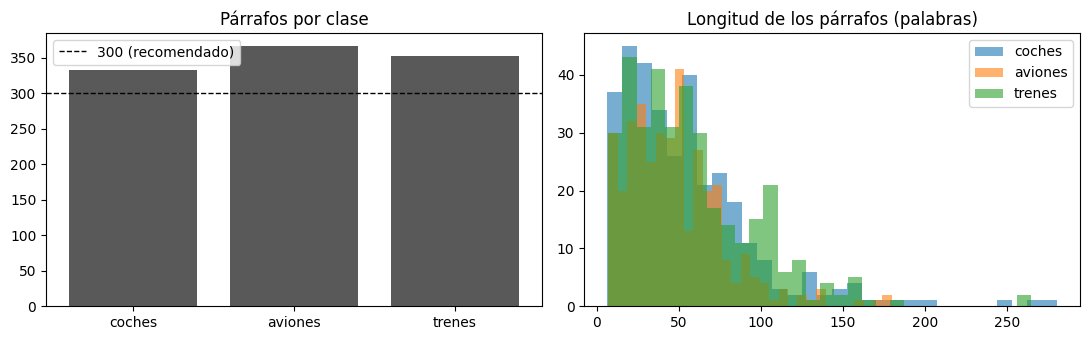

class
coches     333
aviones    367
trenes     352
Longitud media: 53 palabras (mediana 46)


In [6]:
conteo = dataset["class"].value_counts().reindex(CLASES)
palabras = dataset["text"].str.split().str.len()

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].bar(conteo.index, conteo.values, color="0.35")
ejes[0].axhline(300, color="black", linestyle="--", linewidth=1, label="300 (recomendado)")
ejes[0].set_title("Párrafos por clase")
ejes[0].legend()
for clase in CLASES:
    ejes[1].hist(palabras[dataset["class"] == clase], bins=30, alpha=0.6, label=clase)
ejes[1].set_title("Longitud de los párrafos (palabras)")
ejes[1].legend()
plt.tight_layout()
plt.show()

print(conteo.to_string())
print(f"Longitud media: {palabras.mean():.0f} palabras (mediana {palabras.median():.0f})")

### 1.5 Ruido del etiquetado

Cada párrafo **hereda la etiqueta de su artículo**. Esto mete ruido: un artículo sobre un tren puede tener párrafos genéricos ("La kompanio estis fondita en 1950") que no dicen nada de trenes. Lo medimos de tres formas:

1. **Raíces de la clase**: porcentaje de párrafos que no contienen ninguna raíz típica de su categoría (`aŭt`, `aviad`, `trajn`…), buscada también dentro de compuestos (`pasaĝeraviadilo`, `vaporlokomotivo`). Es una cota alta: un párrafo puede hablar de su tema sin esas palabras, por ejemplo citando solo un modelo.
2. **Restos de la limpieza**: párrafos con huecos como `( )` o `. .`, que quedan al quitar enlaces o fechas.
3. **Desacuerdo con el modelo** (sección 5.2): párrafos que un modelo que no ha visto su artículo asigna a otra clase.

In [7]:
RAICES = {
    "coches": "aŭt|ŝofor|stir|karoseri|kamion|buso",
    "aviones": "aviad|aeroplan|flug|pilot|alteriĝ|aerarme|helikopter|jet",
    "trenes": "trajn|lokomotiv|fervoj|vagon|relo|stacidom|metroo|tram",
}

# True si el párrafo no contiene ninguna raíz de su clase
sin_raiz = pd.Series([re.search(RAICES[clase], texto.lower()) is None
                      for texto, clase in zip(dataset["text"], dataset["class"])])

restos = dataset["text"].str.contains(r"\(\s*[.,;]?\s*\)|\s\.\s\.|\.\.\s")

ruido = pd.DataFrame({"sin raíz de su clase (%)": sin_raiz, "restos de limpieza (%)": restos})
tabla_ruido = ruido.groupby(dataset["class"]).mean().reindex(CLASES) * 100
tabla_ruido.loc["total"] = ruido.mean() * 100
display(tabla_ruido.round(1))

print("Ejemplos de párrafos sin ninguna raíz de su clase:")
for clase in CLASES:
    ejemplo = dataset[(dataset["class"] == clase) & sin_raiz].sample(1, random_state=SEMILLA)
    print(f"[{clase}] {ejemplo['text'].iloc[0][:140]}...")

,sin raíz de su clase (%),restos de limpieza (%)
class,,
coches,35.4,0.3
aviones,7.4,0.3
trenes,8.0,0.6
total,16.4,0.4


Ejemplos de párrafos sin ninguna raíz de su clase:
[coches] LADA Vesta havas tri ĉefajn versiojn: Classic (la baza), Comfort (la meza) kaj Luxe (la pinta). Por limuzino haveblas ankaŭ la simpligita ve...
[aviones] Produktado de A300 estis haltigita en 2007, kune kun malgrandigita modelo, A310. Nuntempe usona loĝistika kompanio FedEx Express operacias 6...
[trenes] Malsimila al la cetero de la hispana 1672 mm reto, la AVE uzas la normalan ŝpuron de 1435 mm....


Los coches tienen mucho más ruido por esta medida porque la mayoría de sus artículos son de modelos concretos (*LADA Vesta*, *Fiat 500*) que hablan de versiones, motores o ventas sin decir *aŭto*. En trenes y aviones el porcentaje es bajo, pero en parte porque en los artículos generales ya filtramos por esas mismas raíces (sección 1.2), así que para esas dos clases la medida es optimista. La sección 5.2 da una estimación independiente.

## 2. Modelo de NLP (Fase 2)

Construimos desde cero, sin spaCy ni NLTK, un analizador **basado en reglas** con la misma API que spaCy (tema 2.2): `doc = nlp(texto)`, y para cada token `text`, `lemma_`, `pos_` e `is_stop`, más `doc.sents` para las frases. Aprovechamos que la gramática del esperanto no tiene excepciones: la terminación de cada palabra dice su categoría.

### 2.1 Léxico de la guía y stop-words

El léxico de la guía de la práctica (`vortoj.json`) tiene las palabras gramaticales con su categoría (`kategorio`) y si son palabras vacías (`ignorinda`). Guarda raíces, no formas: tiene *mi* pero no *min* ni *mia*, y *esti* pero no *estas*. Por eso generamos las formas que faltan con las reglas de la gramática: acusativo y posesivo de los pronombres, tiempos verbales, ordinales y la tabla de correlativos (5 prefijos × 9 finales).

In [8]:
URL_VORTOJ = f"https://raw.githubusercontent.com/{REPO}/{VERSION}/src/eonlp/resources/vortoj.json"
vortoj = requests.get(URL_VORTOJ, headers=CABECERAS, timeout=20).json()["vortoj"]

TERMINACIONES_VERBO = ("as", "is", "os", "us", "u", "i")
PREFIJOS_CORRELATIVOS = ["ki", "ti", "i", "ĉi", "neni"]
FINALES_CORRELATIVOS = ["o", "u", "a", "es", "e", "am", "al", "el", "om"]


def formas_pronombre(pronombre):
    # mi -> mi, min, mia, miaj, mian, miajn
    return [pronombre + final for final in ["", "n", "a", "aj", "an", "ajn"]]


def formas_verbo(infinitivo):
    # esti -> estas, estis, estos, estus, estu, esti
    return [infinitivo[:-1] + final for final in TERMINACIONES_VERBO]


def formas_numero(cardinal):
    # unu -> unu, unua, unuaj, unuan, unuajn (ordinales)
    return [cardinal + final for final in ["", "a", "aj", "an", "ajn"]]


STOP_WORDS = set()
for entrada in vortoj:
    if entrada.get("ignorinda"):
        if entrada["kategorio"] == "pronomo":
            STOP_WORDS.update(formas_pronombre(entrada["vorto"]))
        elif entrada["kategorio"] == "verboformo":
            STOP_WORDS.update(formas_verbo(entrada["vorto"]))
        elif entrada["kategorio"] == "nombro":
            STOP_WORDS.update(formas_numero(entrada["vorto"]))
        else:
            STOP_WORDS.add(entrada["vorto"])

# Correlativos: los de -u y -a admiten -j y -n (kiujn), los de -o y -e solo -n (kion, kien)
for prefijo in PREFIJOS_CORRELATIVOS:
    for final in FINALES_CORRELATIVOS:
        palabra = prefijo + final
        STOP_WORDS.add(palabra)
        if final in ("u", "a"):
            STOP_WORDS.update([palabra + "j", palabra + "n", palabra + "jn"])
        elif final in ("o", "e"):
            STOP_WORDS.add(palabra + "n")

print(len(vortoj), "palabras en el léxico de la guía ->", len(STOP_WORDS), "stop-words")

126 palabras en el léxico de la guía -> 337 stop-words


### 2.2 Tokenizador y división en frases

1. **Normalizar**: Unicode NFC (una "ĉ" puede venir como un carácter o como "c" + acento) y **sistema x** (`cx` = `ĉ`, porque en esperanto no existe la x). El sistema x solo se aplica si el texto no tiene ya letras con acento, para no estropear palabras como *Linux*.
2. **Tokenizar** con expresiones regulares (tema 1.3). Primero se prueba un lexicón de abreviaturas ordenadas de más larga a más corta (regla *longest-match*: `k.t.p.` antes que `p.`), y después números, palabras y signos.
3. **Dividir en frases**: una frase acaba en `.`, `!`, `?` o `...`, salvo que el punto vaya detrás de una inicial (*J. Smith*) o delante de una minúscula.

In [9]:
SISTEMA_X = {"cx": "ĉ", "gx": "ĝ", "hx": "ĥ", "jx": "ĵ", "sx": "ŝ", "ux": "ŭ",
             "Cx": "Ĉ", "Gx": "Ĝ", "Hx": "Ĥ", "Jx": "Ĵ", "Sx": "Ŝ", "Ux": "Ŭ",
             "CX": "Ĉ", "GX": "Ĝ", "HX": "Ĥ", "JX": "Ĵ", "SX": "Ŝ", "UX": "Ŭ"}


def normalizar(texto):
    texto = unicodedata.normalize("NFC", texto)
    if not any(letra in texto for letra in "ĉĝĥĵŝŭĈĜĤĴŜŬ"):
        for x, letra in SISTEMA_X.items():
            texto = texto.replace(x, letra)
    return texto


ABREVIATURAS = ["k.t.p.", "ktp.", "k.c.", "kc.", "ekz.", "t.e.", "t.n.", "i.a.", "vd.", "inkl.",
                "trad.", "p.K.", "a.K.", "a.n.e.", "n.e.", "jc.", "ĉ.", "pp.", "p.", "n.",
                "Mk.", "Co.", "Ref.", "Nr.", "St."]
ABREVIATURAS = ABREVIATURAS + [a[0].upper() + a[1:] for a in ABREVIATURAS]   # por si empiezan frase
ABREVIATURAS = sorted(set(ABREVIATURAS), key=len, reverse=True)              # longest-match

PATRON_TOKEN = re.compile(
    "|".join(re.escape(a) for a in ABREVIATURAS)
    + r"|\d+(?:[.,]\d+)+"     # números con separador: 1.000, 3,5
    + r"|[Ll]['’]"            # artículo con elisión: l'
    + r"|\w+(?:-\w+)*"        # palabras, también con guion: 29-an, F-16
    + r"|\.\.\.|…"            # puntos suspensivos
    + r"|[^\w\s]"             # cualquier otro signo, de uno en uno
)


def tokenizar(texto):
    # Lista de (token, posición de su primer carácter en el texto)
    return [(m.group(), m.start()) for m in PATRON_TOKEN.finditer(texto)]


FINALES_DE_FRASE = {".", "!", "?", "...", "…"}
CIERRES = {")", "]", "»", "”", '"', "'"}


def dividir_frases(tokens):
    # Devuelve pares (inicio, fin) con las posiciones de los tokens de cada frase
    limites = []
    inicio = 0
    i = 0
    while i < len(tokens):
        token = tokens[i]
        es_final = token in FINALES_DE_FRASE
        if token == "." and i > 0 and len(tokens[i - 1]) == 1 and tokens[i - 1].isupper():
            es_final = False      # inicial: "J. Smith"
        if token == "." and i + 1 < len(tokens) and tokens[i + 1][0].islower():
            es_final = False      # detrás viene minúscula: no acaba la frase
        if token in ("k.t.p.", "ktp.") and i + 1 < len(tokens) and tokens[i + 1][0].isupper():
            es_final = True       # "k.t.p." al final de una frase
        if es_final:
            while i + 1 < len(tokens) and tokens[i + 1] in CIERRES:
                i += 1            # el paréntesis o las comillas que cierran van con la frase
            limites.append((inicio, i + 1))
            inicio = i + 1
        i += 1
    if inicio < len(tokens):
        limites.append((inicio, len(tokens)))
    return limites


print(tokenizar("La trajno, ekz. TGV, veturas 320 km/h."))
print(dividir_frases(["Ĝi", "venis", ".", "Ni", "iris", "."]))

[('La', 0), ('trajno', 3), (',', 9), ('ekz.', 11), ('TGV', 16), (',', 19), ('veturas', 21), ('320', 29), ('km', 33), ('/', 35), ('h', 36), ('.', 37)]
[(0, 3), (3, 6)]


### 2.3 Etiquetador (POS)

Usa las etiquetas universales de spaCy (`NOUN`, `VERB`, `ADJ`, `ADV`, `PRON`, `DET`, `ADP`…). Las reglas se aplican de la más segura a la más general:

1. Signos (`PUNCT`) y números (`NUM`).
2. Palabras gramaticales: se buscan en un **lexicón** construido con el léxico de la guía y las formas generadas en 2.1. Los pronombres posesivos (*mia*) son `DET`, los ordinales (*unua*) `ADJ` y *esti* es `AUX`.
3. Palabras gramaticales con prefijo `mal-` o `ek-`: *malpli* se etiqueta como *pli*.
4. Nombres propios (`PROPN`): siglas (*TGV*), nombres con cifras (*A380*) y palabras en mayúscula que no empiezan la frase (*Boeing*).
5. **Terminación**, quitando antes `-n` (acusativo) y `-j` (plural): `-o` sustantivo, `-a` adjetivo, `-e` adverbio, `-as/-is/-os/-us/-u/-i` verbo.

In [10]:
CATEGORIA_A_POS = {"artikolo": "DET", "prepozicio": "ADP", "konjunkcio": "CCONJ", "pronomo": "PRON",
                   "adverbo": "ADV", "partikulo": "PART", "verboformo": "VERB", "nombro": "NUM",
                   "interjekcio": "INTJ", "ĝentilaĵo": "INTJ", "titolo": "NOUN"}
SUBORDINANTES = {"ke", "se", "ĉar", "kvankam", "kvazaŭ"}
# Correlativos: cosa o persona -> PRON, clase o posesión -> DET, lugar, tiempo, modo... -> ADV
POS_CORRELATIVO = {"o": "PRON", "u": "PRON", "a": "DET", "es": "DET",
                   "e": "ADV", "am": "ADV", "al": "ADV", "el": "ADV", "om": "ADV"}
POS_ABREVIATURAS = {"ekz.": "ADV", "t.e.": "ADV", "ĉ.": "ADV", "ktp.": "ADV", "k.t.p.": "ADV",
                    "i.a.": "ADV", "inkl.": "ADV", "vd.": "VERB"}
UNIDADES = {"km", "m", "cm", "mm", "kg", "t", "h", "s", "kw", "kv", "kvt", "ĉp", "l"}

LEXICON = {}
for entrada in vortoj:
    palabra, categoria = entrada["vorto"], entrada["kategorio"]
    if categoria == "konjunkcio" and palabra in SUBORDINANTES:
        LEXICON[palabra] = "SCONJ"
    elif categoria == "pronomo":
        for forma in formas_pronombre(palabra):
            LEXICON[forma] = "PRON" if forma in (palabra, palabra + "n") else "DET"
    elif categoria == "verboformo":
        for forma in formas_verbo(palabra):
            LEXICON[forma] = "AUX" if palabra == "esti" else "VERB"
    elif categoria == "nombro":
        for forma in formas_numero(palabra):
            LEXICON[forma] = "NUM" if forma == palabra else "ADJ"
    else:
        LEXICON[palabra] = CATEGORIA_A_POS[categoria]
for prefijo in PREFIJOS_CORRELATIVOS:
    for final, pos in POS_CORRELATIVO.items():
        for extra in ["", "j", "n", "jn"]:
            LEXICON[prefijo + final + extra] = pos
LEXICON["l'"] = "DET"
LEXICON.update(POS_ABREVIATURAS)
for unidad in UNIDADES:
    LEXICON[unidad] = "NOUN"


def etiquetar(palabra, inicio_frase=False):
    if not any(c.isalnum() for c in palabra):
        return "PUNCT"
    if not any(c.isalpha() for c in palabra) and any(c.isnumeric() for c in palabra):
        return "NUM"

    minuscula = palabra.lower()
    if minuscula in LEXICON:
        return LEXICON[minuscula]
    for prefijo in ("mal", "ek"):
        resto = minuscula[len(prefijo):]
        if minuscula.startswith(prefijo) and resto in LEXICON:
            return LEXICON[resto]

    tiene_letras = any(c.isalpha() for c in palabra)
    tiene_cifras = any(c.isdigit() for c in palabra)
    if tiene_letras and tiene_cifras and palabra[0].isupper():   # A380, F-16
        return "PROPN"
    if len(palabra) > 1 and palabra.isupper():                   # TGV, SNCF
        return "PROPN"
    if palabra[0].isupper() and not inicio_frase:                # Boeing, Parizo
        return "PROPN"

    if len(minuscula) >= 3:
        if minuscula.endswith(TERMINACIONES_VERBO):
            return "VERB"
        raiz = minuscula
        if raiz.endswith("n"):     # acusativo
            raiz = raiz[:-1]
        if raiz.endswith("j"):     # plural
            raiz = raiz[:-1]
        if raiz.endswith("o"):
            return "NOUN"
        if raiz.endswith("a"):
            return "ADJ"
        if raiz.endswith(("e", "aŭ")):
            return "ADV"
    if palabra[0].isupper():       # mayúscula al inicio de frase sin terminación del esperanto
        return "PROPN"
    return "X"


print([etiquetar(p) for p in ["la", "trajno", "rapida", "veturas", "tre", "rapide", "malpli", "Boeing"]])

['DET', 'NOUN', 'ADJ', 'VERB', 'ADV', 'ADV', 'ADV', 'PROPN']


### 2.4 Lematizador

El lema es la forma de diccionario (tema 2.2). No es *stemming*: de *librojn* el *stemming* daría la raíz *libr*, y el lema es *libro*. Según la categoría del etiquetador:

- Pronombres, ordinales y correlativos: tabla generada con las reglas de 2.1 (*min → mi*, *tiujn → tiu*).
- Verbos: la terminación de tiempo se cambia por `-i` (*veturis → veturi*).
- Sustantivos y adjetivos: se quitan `-n` y `-j` (*librojn → libro*).
- Nombres propios: solo se quita el acusativo (*Parizon → Parizo*).

In [11]:
LEMAS = {}
for entrada in vortoj:
    palabra = entrada["vorto"]
    if entrada["kategorio"] == "pronomo":
        for forma in formas_pronombre(palabra):
            LEMAS[forma] = palabra if forma in (palabra, palabra + "n") else palabra + "a"
    elif entrada["kategorio"] == "nombro":
        for forma in formas_numero(palabra):
            LEMAS[forma] = palabra if forma == palabra else palabra + "a"
for prefijo in PREFIJOS_CORRELATIVOS:
    for final in FINALES_CORRELATIVOS:
        for extra in ["", "j", "n", "jn"]:
            LEMAS[prefijo + final + extra] = prefijo + final
LEMAS["l'"] = "la"


def quitar_flexion(palabra):
    if palabra.endswith("n") and len(palabra) > 2:
        palabra = palabra[:-1]
    if palabra.endswith("j") and len(palabra) > 2:
        palabra = palabra[:-1]
    return palabra


def lematizar(palabra, pos):
    minuscula = palabra.lower()
    if minuscula in LEMAS:
        return LEMAS[minuscula]
    if pos in ("VERB", "AUX"):
        for final in TERMINACIONES_VERBO:
            if minuscula.endswith(final):
                return minuscula[:-len(final)] + "i"
        return minuscula
    if pos in ("NOUN", "ADJ"):
        return quitar_flexion(minuscula)
    if pos == "PROPN":
        # Parizon -> Parizo, pero Boeing, TGV o A380 no cambian
        return quitar_flexion(palabra) if palabra.endswith(("on", "ojn", "oj")) else palabra
    return minuscula


print([lematizar(p, etiquetar(p)) for p in ["librojn", "kantis", "rapidajn", "min", "tiujn"]])

['libro', 'kanti', 'rapida', 'mi', 'tiu']


### 2.5 Objetos `Doc` y `Token` y función `nlp`

`Token` y `Doc` son clases normales con los métodos especiales del tema 0.1 (`__init__`, `__len__`, `__getitem__`, `__str__`). Con `__getitem__` ya se puede recorrer un `Doc` con `for`. Las frases (`doc.sents`) son a su vez objetos `Doc`, así que `frase.text` funciona igual que en spaCy.

In [12]:
class Token:
    def __init__(self, texto, posicion):
        self.text = texto
        self.idx = posicion        # posición de su primer carácter en el texto
        self.pos_ = ""
        self.lemma_ = texto
        self.is_stop = False
        self.is_punct = not any(c.isalnum() for c in texto)

    def __str__(self):
        return self.text


class Doc:
    def __init__(self, texto, tokens):
        self.text = texto
        self.tokens = tokens
        self.sents = []            # frases, cada una como otro Doc

    def __len__(self):
        return len(self.tokens)

    def __getitem__(self, i):
        return self.tokens[i]

    def __str__(self):
        return self.text


def nlp(texto):
    texto = normalizar(texto)
    tokens = [Token(t, posicion) for t, posicion in tokenizar(texto)]
    limites = dividir_frases([t.text for t in tokens])

    # Primera palabra de cada frase: su mayúscula no indica nombre propio
    inicios = set()
    for desde, hasta in limites:
        for i in range(desde, hasta):
            if not tokens[i].is_punct:
                inicios.add(i)
                break

    # Primero la categoría, porque el lematizador la necesita
    for i, token in enumerate(tokens):
        token.pos_ = etiquetar(token.text, i in inicios)
        token.lemma_ = lematizar(token.text, token.pos_)
        token.is_stop = token.text.lower() in STOP_WORDS

    doc = Doc(texto, tokens)
    for desde, hasta in limites:
        primero, ultimo = tokens[desde], tokens[hasta - 1]
        doc.sents.append(Doc(texto[primero.idx:ultimo.idx + len(ultimo.text)], tokens[desde:hasta]))
    return doc

### 2.6 Ejemplo y análisis del dataset

In [13]:
ejemplo = nlp("La rapidaj trajnoj veturis al Madrido. Ĉiuj aviadiloj de Boeing flugas tre alte!")
display(pd.DataFrame(
    [(t.text, t.lemma_, t.pos_, t.is_stop, t.is_punct) for t in ejemplo],
    columns=["text", "lemma_", "pos_", "is_stop", "is_punct"],
))
print("Frases:", [frase.text for frase in ejemplo.sents])

,text,lemma_,pos_,is_stop,is_punct
0,La,la,DET,True,False
1,rapidaj,rapida,ADJ,False,False
2,trajnoj,trajno,NOUN,False,False
3,veturis,veturi,VERB,False,False
4,al,al,ADP,True,False
5,Madrido,Madrido,PROPN,False,False
6,.,.,PUNCT,False,True
7,Ĉiuj,ĉiu,PRON,True,False
8,aviadiloj,aviadilo,NOUN,False,False
9,de,de,ADP,True,False


Frases: ['La rapidaj trajnoj veturis al Madrido.', 'Ĉiuj aviadiloj de Boeing flugas tre alte!']


In [14]:
# Analizamos todo el dataset una sola vez y reutilizamos el resultado
docs = [nlp(texto) for texto in dataset["text"]]

palabras_dataset = [t for doc in docs for t in doc if not t.is_punct]
formas = {t.text.lower() for t in palabras_dataset}
lemas = {t.lemma_.lower() for t in palabras_dataset}
print("Tokens en el dataset:", sum(len(doc) for doc in docs))
print(f"Stop-words: {100 * np.mean([t.is_stop for t in palabras_dataset]):.1f} % de las palabras")
print(f"Vocabulario: {len(formas)} formas distintas -> {len(lemas)} lemas ({100 * (1 - len(lemas) / len(formas)):.0f} % menos)")

Tokens en el dataset: 64718
Stop-words: 40.1 % de las palabras
Vocabulario: 11622 formas distintas -> 9265 lemas (20 % menos)


### 2.7 La misma librería, instalable con `pip` (extra 9.1)

El código de esta sección está publicado como la librería `eonlp` en nuestro repositorio (`src/eonlp`), con tests y documentación. La instalamos y comprobamos que analiza todo el dataset exactamente igual que el cuaderno (tokens, lemas, categorías, stop-words y frases). Si no hay conexión, el cuaderno sigue con su propio código.

In [15]:
!pip install -q "git+https://github.com/{REPO}.git@{VERSION}"

try:
    import eonlp
    nlp_libreria = eonlp.load()
    iguales = True
    for texto, doc in zip(dataset["text"], docs):
        doc_libreria = nlp_libreria(texto)
        if [(t.text, t.lemma_, t.pos_, t.is_stop) for t in doc_libreria] != [(t.text, t.lemma_, t.pos_, t.is_stop) for t in doc]:
            iguales = False
        if [f.text for f in doc_libreria.sents] != [f.text for f in doc.sents]:
            iguales = False
    print("eonlp", eonlp.__version__, "da el mismo resultado que el cuaderno:", iguales)
except ImportError:
    print("No se pudo instalar la librería. El cuaderno usa su propio código.")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
eonlp 0.1.0 da el mismo resultado que el cuaderno: True


## 3. Vectorización (Fase 3)

Seguimos los cinco pasos del tema 2.3 para pasar un texto a un vector:

1. **Tokenizar** con nuestro `nlp` (sección 2).
2. **Filtrar** stop-words, signos de puntuación y números.
3. **Normalizar**: minúsculas y **lema** (`trajno`, `trajnoj` y `trajnojn` cuentan como la misma palabra).
4. **Representar** cada palabra con *one-hot* sobre un **vocabulario**: los 1000 lemas más frecuentes del **entrenamiento**.
5. **Vectorizar el texto** con la media de sus vectores one-hot, es decir, la **frecuencia relativa** de cada palabra (el vector suma 1, así no influye la longitud del párrafo).

Comparamos las dos representaciones del tema 2.4:

- **BoW normalizada**: el paso 5 tal cual.
- **TF-IDF por clases**, la versión de la asignatura: `IDF(t) = 1 − log_|C|(máx(1, nº de clases que contienen t))`. Con 3 clases, una palabra que solo sale en una clase pesa 1; en dos, 0,37; en las tres, 0. Después se vuelve a normalizar para que el vector sume 1.

El vocabulario y el IDF se calculan **solo con el entrenamiento**, para no usar información del test.

In [16]:
def preprocesar(doc):
    # Pasos 1-3: lemas en minúsculas de las palabras con contenido
    return [t.lemma_.lower() for t in doc
            if not t.is_stop and not t.is_punct and t.pos_ not in ("PUNCT", "NUM", "X")]


lemas_por_parrafo = [preprocesar(doc) for doc in docs]
y = dataset["class"].to_numpy()

print(dataset["text"].iloc[0][:120], "...")
print("->", lemas_por_parrafo[0][:15])

Aŭtomobilo (el la greka autos [mem] kaj latina mobilis [mobila]) aŭ (kiel kutima mallongigita formo) aŭto estas, krom bi ...
-> ['aŭtomobilo', 'greka', 'auti', 'latina', 'mobili', 'mobila', 'kutima', 'mallongigita', 'formo', 'aŭto', 'biciklo', 'ofte', 'uzata', 'veturilo', 'persona']


In [17]:
def crear_vocabulario(lista_lemas):
    # Paso 4: los lemas más frecuentes
    frecuencias = Counter(lema for lemas in lista_lemas for lema in lemas)
    return [lema for lema, _ in frecuencias.most_common(TAMANO_VOCABULARIO)]


def calcular_idf(lista_lemas, clases, vocabulario):
    # IDF de la asignatura: 1 - log_|C|(nº de clases en las que aparece la palabra)
    lemas_de_clase = {clase: set() for clase in CLASES}
    for lemas, clase in zip(lista_lemas, clases):
        lemas_de_clase[clase].update(lemas)
    n_clases = np.array([max(1, sum(lema in lemas_de_clase[c] for c in CLASES)) for lema in vocabulario])
    return 1 - np.log(n_clases) / np.log(len(CLASES))


def vectorizar(lista_lemas, vocabulario, idf=None):
    # Paso 5: frecuencia relativa de cada lema del vocabulario (con idf=None es la BoW)
    posicion = {lema: i for i, lema in enumerate(vocabulario)}
    X = np.zeros((len(lista_lemas), len(vocabulario)))
    for fila, lemas in enumerate(lista_lemas):
        for lema in lemas:
            if lema in posicion:
                X[fila, posicion[lema]] += 1
    if idf is not None:
        X = X * idf
    totales = X.sum(axis=1, keepdims=True)
    totales[totales == 0] = 1      # un texto sin palabras del vocabulario se queda en ceros
    return X / totales

In [18]:
# Partición train/test estratificada (misma proporción de clases en los dos), tema 0.4
indices = np.arange(len(dataset))
i_train, i_test = train_test_split(indices, test_size=PROPORCION_TEST, random_state=SEMILLA, stratify=y)
lemas_train = [lemas_por_parrafo[i] for i in i_train]
lemas_test = [lemas_por_parrafo[i] for i in i_test]
print(f"Entrenamiento: {len(i_train)} párrafos · Test: {len(i_test)} párrafos")

vocabulario = crear_vocabulario(lemas_train)
idf = pd.Series(calcular_idf(lemas_train, y[i_train], vocabulario), index=vocabulario)
print("Matriz de entrenamiento:", vectorizar(lemas_train, vocabulario).shape)

print("\nIDF por clases del vocabulario (nº de lemas):")
print(idf.round(2).value_counts().sort_index().to_string())
print("\nIDF = 1 (una sola clase):", list(idf[idf == 1].index[:12]))
print("IDF = 0 (las tres clases):", list(idf[idf == 0].index[:12]))

Entrenamiento: 841 párrafos · Test: 211 párrafos
Matriz de entrenamiento: (841, 1000)

IDF por clases del vocabulario (nº de lemas):
0.00    431
0.37    284
1.00    285

IDF = 1 (una sola clase): ['boeing', 'fervojo', 'pasaĝeraviadilo', 'airbus', 'ĉasaviadilo', 'lada', 'aerarmeo', 'flugo', 'douglas', 'dsb', 'vaporlokomotivo', 'fervoja']
IDF = 0 (las tres clases): ['aviadilo', 'jaro', 'nova', 'motoro', 'modelo', 'km', 'alia', 'elektra', 'granda', 'uzi', 'poste', 'versio']


## 4. Entrenamiento y selección del modelo

Probamos los cuatro clasificadores del tema 0.4 con las dos vectorizaciones, con **validación cruzada de 5 particiones** (`KFold`) **sobre el entrenamiento**. En cada partición el vocabulario y el IDF se recalculan solo con su parte de entrenamiento. El test no se toca hasta la sección 5. Elegimos la combinación con mejor **F1 macro**.

In [19]:
MODELOS = {
    "Regresión logística": lambda: LogisticRegression(max_iter=1000, random_state=SEMILLA),
    "Naive Bayes": lambda: GaussianNB(),
    "KNN (k=5)": lambda: KNeighborsClassifier(n_neighbors=5),
    "Árbol de decisión": lambda: DecisionTreeClassifier(random_state=SEMILLA),
}


def entrenar(indices_train, metodo, nombre_modelo):
    # Vocabulario, IDF y modelo aprendidos solo con los párrafos de entrenamiento
    lemas = [lemas_por_parrafo[i] for i in indices_train]
    vocabulario = crear_vocabulario(lemas)
    idf = calcular_idf(lemas, y[indices_train], vocabulario) if metodo == "tfidf" else None
    modelo = MODELOS[nombre_modelo]().fit(vectorizar(lemas, vocabulario, idf), y[indices_train])
    return modelo, vocabulario, idf


filas = []
kfold = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
for metodo in ["bow", "tfidf"]:
    for nombre in MODELOS:
        accuracies, f1s = [], []
        for parte_train, parte_val in kfold.split(i_train):
            i_tr, i_va = i_train[parte_train], i_train[parte_val]
            modelo, vocabulario, idf = entrenar(i_tr, metodo, nombre)
            prediccion = modelo.predict(vectorizar([lemas_por_parrafo[i] for i in i_va], vocabulario, idf))
            accuracies.append(accuracy_score(y[i_va], prediccion))
            f1s.append(f1_score(y[i_va], prediccion, average="macro"))
        filas.append([metodo.upper(), nombre, np.mean(accuracies), np.mean(f1s)])

comparacion = pd.DataFrame(filas, columns=["vectorización", "modelo", "accuracy", "F1 macro"])
comparacion = comparacion.sort_values("F1 macro", ascending=False).reset_index(drop=True)
comparacion.round(3)

,vectorización,modelo,accuracy,F1 macro
0,TFIDF,Regresión logística,0.956,0.956
1,BOW,Regresión logística,0.937,0.936
2,TFIDF,Naive Bayes,0.920,0.918
3,BOW,Naive Bayes,0.912,0.911
4,BOW,Árbol de decisión,0.874,0.875
5,TFIDF,Árbol de decisión,0.866,0.868
6,BOW,KNN (k=5),0.837,0.840
7,TFIDF,KNN (k=5),0.831,0.830


In [20]:
METODO = comparacion.loc[0, "vectorización"].lower()
NOMBRE_MODELO = comparacion.loc[0, "modelo"]
print(f"Modelo elegido: {NOMBRE_MODELO} + {METODO.upper()} (F1 macro {comparacion.loc[0, 'F1 macro']:.3f})")

# Entrenamiento final con todo el conjunto de entrenamiento
modelo, vocabulario, idf = entrenar(i_train, METODO, NOMBRE_MODELO)
X_test = vectorizar(lemas_test, vocabulario, idf)

Modelo elegido: Regresión logística + TFIDF (F1 macro 0.956)


## 5. Evaluación

### 5.1 Conjunto de test

Métricas pedidas: **accuracy** (aciertos totales), **F1 macro** (media del F1 de las tres clases, sin que pese más la clase más grande) y **matriz de confusión**.

Accuracy: 0.929 · F1 macro: 0.929

              precision    recall  f1-score   support

      coches      0.877     0.955     0.914        67
     aviones      0.958     0.932     0.945        74
      trenes      0.955     0.900     0.926        70

    accuracy                          0.929       211
   macro avg      0.930     0.929     0.929       211
weighted avg      0.931     0.929     0.929       211



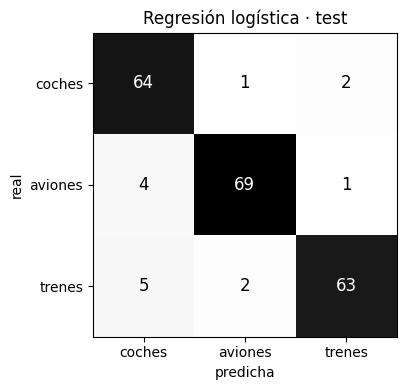

In [21]:
def dibujar_matriz(reales, predichas, titulo, eje):
    matriz = confusion_matrix(reales, predichas, labels=CLASES)
    eje.imshow(matriz, cmap="Greys")
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            color = "white" if matriz[i, j] > matriz.max() / 2 else "black"
            eje.text(j, i, matriz[i, j], ha="center", va="center", color=color, fontsize=12)
    eje.set_xticks(range(len(CLASES)), CLASES)
    eje.set_yticks(range(len(CLASES)), CLASES)
    eje.set_xlabel("predicha")
    eje.set_ylabel("real")
    eje.set_title(titulo)


prediccion_test = modelo.predict(X_test)
accuracy_test = accuracy_score(y[i_test], prediccion_test)
f1_test = f1_score(y[i_test], prediccion_test, average="macro")
print(f"Accuracy: {accuracy_test:.3f} · F1 macro: {f1_test:.3f}\n")
print(classification_report(y[i_test], prediccion_test, labels=CLASES, digits=3))

fig, eje = plt.subplots(figsize=(4.5, 4))
dibujar_matriz(y[i_test], prediccion_test, f"{NOMBRE_MODELO} · test", eje)
plt.tight_layout()
plt.show()

### 5.2 Prueba más exigente: validación cruzada por artículo

En la partición aleatoria, párrafos del **mismo artículo** caen a la vez en train y en test, así que el modelo puede acertar porque "reconoce el artículo" (sus nombres propios, su estilo) y no porque entienda el tema. Para medirlo, repartimos los artículos de cada clase en 5 grupos y hacemos una validación cruzada por grupos: cada párrafo lo clasifica un modelo que **no ha visto ningún párrafo de su artículo**, como pasará con una página web nueva.

Los párrafos mal clasificados aquí son el **desacuerdo con el modelo** de la sección 1.5: una mezcla de ruido del etiquetado y error real del modelo.

,evaluación,párrafos evaluados,accuracy,F1 macro
0,test aleatorio (5.1),211,0.929,0.929
1,validación por artículo (5.2),1052,0.863,0.862


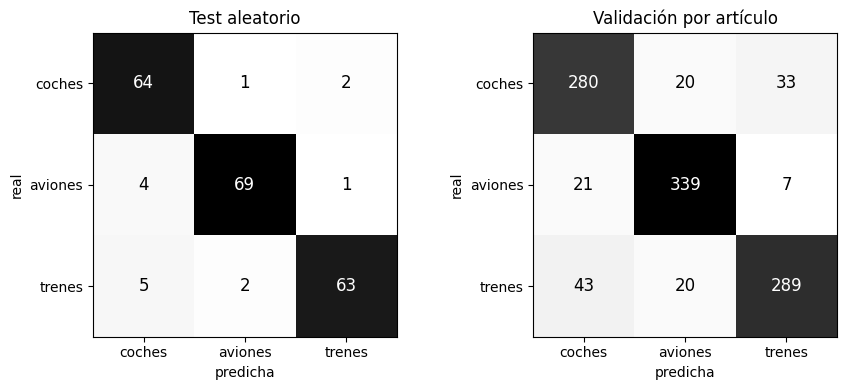

Párrafos asignados a OTRA clase por un modelo que no ha visto su artículo (%):
coches     15.9
aviones     7.6
trenes     17.9
total      13.7


In [22]:
# Repartimos los artículos de cada clase en 5 grupos con la semilla fijada
grupo_de = {}
for clase in CLASES:
    articulos = sorted(metadata.loc[metadata["class"] == clase, "articulo"].unique())
    random.Random(SEMILLA).shuffle(articulos)
    for k, articulo in enumerate(articulos):
        grupo_de[articulo] = k % 5
grupos = metadata["articulo"].map(grupo_de).to_numpy()

prediccion_art = np.empty(len(dataset), dtype=object)
confianza_art = np.zeros(len(dataset))
for grupo in range(5):
    tr, va = indices[grupos != grupo], indices[grupos == grupo]
    m, voc, idf_grupo = entrenar(tr, METODO, NOMBRE_MODELO)
    X_va = vectorizar([lemas_por_parrafo[i] for i in va], voc, idf_grupo)
    prediccion_art[va] = m.predict(X_va)
    confianza_art[va] = m.predict_proba(X_va).max(axis=1)

accuracy_art = accuracy_score(y, prediccion_art)
f1_art = f1_score(y, prediccion_art, average="macro")
display(pd.DataFrame({
    "evaluación": ["test aleatorio (5.1)", "validación por artículo (5.2)"],
    "párrafos evaluados": [len(i_test), len(dataset)],
    "accuracy": [accuracy_test, accuracy_art],
    "F1 macro": [f1_test, f1_art],
}).round(3))

fig, ejes = plt.subplots(1, 2, figsize=(9, 4))
dibujar_matriz(y[i_test], prediccion_test, "Test aleatorio", ejes[0])
dibujar_matriz(y, prediccion_art, "Validación por artículo", ejes[1])
plt.tight_layout()
plt.show()

discrepa = prediccion_art != y
print("Párrafos asignados a OTRA clase por un modelo que no ha visto su artículo (%):")
print((pd.Series(discrepa).groupby(y).mean().reindex(CLASES) * 100).round(1).to_string())
print(f"total      {100 * discrepa.mean():.1f}")

### 5.3 Qué ha aprendido el modelo y dónde falla

Los coeficientes de la regresión logística indican qué lemas empujan hacia cada clase. Debajo, algunos párrafos en los que el modelo de 5.2 no coincide con la etiqueta, con la probabilidad que dio a su predicción.

In [23]:
if NOMBRE_MODELO == "Regresión logística":
    print("Lemas con más peso para cada clase:")
    for k, clase in enumerate(modelo.classes_):
        mejores = np.argsort(modelo.coef_[k])[::-1][:12]
        print(f"  {clase:8} {', '.join(vocabulario[i] for i in mejores)}")

errores = pd.DataFrame({"real": y, "predicha": prediccion_art, "confianza": confianza_art,
                        "text": dataset["text"]})[discrepa]
print("\nEjemplos de desacuerdo:")
for _, fila in errores.sample(6, random_state=SEMILLA).iterrows():
    print(f"  real={fila['real']:8} predicha={fila['predicha']:8} ({fila['confianza']:.2f}) {fila['text'][:100]}...")

Lemas con más peso para cada clase:
  aviones  boeing, ĉasaviadilo, pasaĝeraviadilo, airbus, flugo, aerarmeo, aeroplano, konkordo, piloto, flugilo, jetmotoro, flugi
  coches   aŭto, aŭtomobilo, lada, model, benz, taksio, trabant, porsche, avtovaz, prius, ford, nymph
  trenes   trajno, fervojo, lokomotivo, dsb, vaporlokomotivo, vagono, vagonaro, motortrajno, fervoja, metroo, regiojet, z

Ejemplos de desacuerdo:
  real=trenes   predicha=coches   (0.35) Ukrainio konsideris pri aĉeto en konekso kun aranĝo Eŭropa Pokalo en futbalo 2012. Sed pro manko de ...
  real=coches   predicha=trenes   (0.35) La Fairway estis anstataŭita malfrue en 1997 de la TX1, kiu estis sinsekve anstataŭita en 2002 de la...
  real=trenes   predicha=aviones  (0.35) Oni klopodis por funkciado de variaj aliaj tipoj de trajnpelado, el kiuj kelkaj estis pli sukcesaj o...
  real=trenes   predicha=coches   (0.40) La mondo de la Orient-Express nun estas vere internacia kaj pasaĝeroj povas ĝui similan sperton ĉe l...
  real

Muchos de estos "errores" no son fallos del modelo sino **ruido del dataset**: párrafos genéricos (fechas, empresas, cifras) que no hablan de su vehículo, con una confianza baja, cerca de 1/3, porque el modelo no encuentra ninguna palabra de una clase. Otros hablan de otra categoría (un artículo de trenes que se compara con el avión). También se ve que los nombres propios (*lada*, *trabant*, *boeing*, *dsb*) pesan mucho: ayudan con artículos ya vistos, pero no con textos nuevos, y eso explica parte de la caída de 5.1 a 5.2.

## 6. Clasificación de páginas web

Probamos el modelo con cuatro páginas reales en esperanto **que no están en el dataset**: tres artículos de Wikipedia, uno por clase, y una noticia de **Vikinovaĵoj** (eo.wikinews.org), otra web con otro tipo de texto (economía del automóvil). Para cada página:

1. Se descarga con `requests` con un **User-Agent** que nos identifica (tema 3.2), una sola petición por página y una pausa entre páginas para no cargar el servidor (tema 3.4). Hemos revisado el `robots.txt` de las dos webs: no prohíben las páginas `/wiki/...`.
2. Se extraen los párrafos `<p>` con BeautifulSoup (tema 3.3) y se quitan las llamadas a notas `[1]`.
3. Se clasifica cada párrafo con `predict_proba` y la **probabilidad de cada categoría** para la página es la media de sus párrafos ponderada por su longitud.

Si una página falla (sin conexión, error 4xx/5xx o sin texto), se avisa y se sigue con la siguiente.

OK: Aŭtomobilo-revokoj de Toyota 2009-2010 (16 párrafos)
OK: Aviado (8 párrafos)
OK: Transsiberia fervojo (10 párrafos)
OK: Kia Corp. atingis plej grandan transakcian profiton en sia historio (11 párrafos)


,coches,aviones,trenes
Aŭtomobilo-revokoj de Toyota 2009-2010 (esperada: coches),59.4,21.7,18.9
Aviado (esperada: aviones),24.0,56.5,19.5
Transsiberia fervojo (esperada: trenes),14.1,12.8,73.1
Kia Corp. atingis plej grandan transakci (esperada: coches),53.2,24.7,22.1


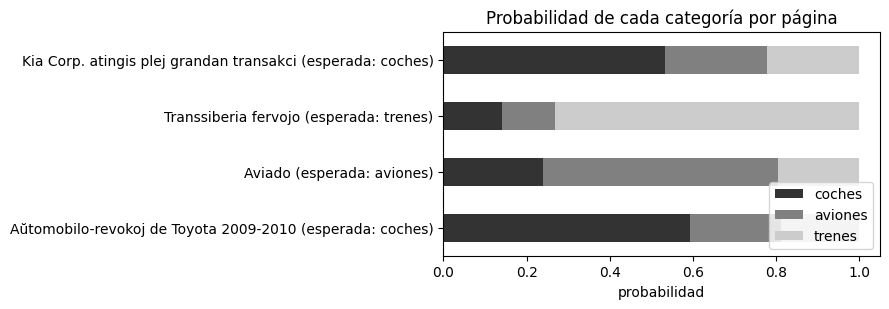

In [24]:
PAGINAS_WEB = [
    ("coches", "Aŭtomobilo-revokoj de Toyota 2009-2010", "https://eo.wikipedia.org/wiki/A%C5%ADtomobilo-revokoj_de_Toyota_2009-2010"),
    ("aviones", "Aviado", "https://eo.wikipedia.org/wiki/Aviado"),
    ("trenes", "Transsiberia fervojo", "https://eo.wikipedia.org/wiki/Transsiberia_fervojo"),
    ("coches", "Kia Corp. atingis plej grandan transakcian profiton en sia historio",
     "https://eo.wikinews.org/wiki/Kia_Corp._atingis_plej_grandan_transakcian_profiton_en_sia_historio"),
]

# Comprobamos que ninguna página forma parte del dataset
for _, titulo, _ in PAGINAS_WEB:
    assert titulo not in set(metadata["articulo"]), titulo


def descargar_parrafos(url):
    respuesta = requests.get(url, headers=CABECERAS, timeout=20)
    respuesta.raise_for_status()
    sopa = BeautifulSoup(respuesta.text, "html.parser")
    contenido = sopa.find("div", {"class": "mw-parser-output"}) or sopa
    parrafos = []
    for p in contenido.find_all("p"):
        texto = re.sub(r"\[\s*\d+\s*\]", "", p.get_text())   # quitar llamadas a notas [1]
        texto = " ".join(texto.split())
        if len(texto.split()) >= 6:
            parrafos.append(texto)
    return parrafos


def clasificar_textos(textos):
    lista_lemas = [preprocesar(nlp(texto)) for texto in textos]
    return modelo.predict_proba(vectorizar(lista_lemas, vocabulario, idf))


resultados_web = {}
for esperada, titulo, url in PAGINAS_WEB:
    try:
        parrafos = descargar_parrafos(url)
    except requests.RequestException as error:
        print(f"Aviso: no se pudo descargar {titulo} ({error})")
        continue
    finally:
        time.sleep(1)
    if not parrafos:
        print(f"Aviso: {titulo} no tiene párrafos de texto")
        continue
    pesos = [len(p.split()) for p in parrafos]
    probabilidades = np.average(clasificar_textos(parrafos), axis=0, weights=pesos)
    resultados_web[f"{titulo[:40]} (esperada: {esperada})"] = pd.Series(probabilidades, index=modelo.classes_)
    print(f"OK: {titulo} ({len(parrafos)} párrafos)")

if resultados_web:
    tabla_web = pd.DataFrame(resultados_web).T[CLASES]
    display((tabla_web * 100).round(1))
    tabla_web.plot.barh(stacked=True, figsize=(9, 0.8 + 0.6 * len(tabla_web)), color=["0.2", "0.5", "0.8"])
    plt.xlabel("probabilidad")
    plt.title("Probabilidad de cada categoría por página")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
else:
    print("No se pudo descargar ninguna página. Abajo se clasifican textos de ejemplo.")

Textos escritos por nosotros: sirven para ver `predict_proba` aunque no haya conexión. El último es un párrafo genérico, como los que meten ruido en el dataset.

In [25]:
TEXTOS_PROPIOS = [
    "La nova elektra aŭto havas potencan motoron kaj povas veturi 500 kilometrojn.",
    "La pasaĝeroj eniris la aviadilon, kaj post unu horo ĝi alteriĝis en la flughaveno.",
    "La rapida trajno haltis en la stacidomo, kaj la lokomotivo tiris dek vagonojn.",
    "La kompanio estis fondita en 1950 en Germanio.",
]
probabilidades = pd.DataFrame(clasificar_textos(TEXTOS_PROPIOS), columns=modelo.classes_, index=TEXTOS_PROPIOS)
(probabilidades[CLASES] * 100).round(1)

,coches,aviones,trenes
La nova elektra aŭto havas potencan motoron kaj povas veturi 500 kilometrojn.,90.0,5.2,4.8
"La pasaĝeroj eniris la aviadilon, kaj post unu horo ĝi alteriĝis en la flughaveno.",20.9,59.3,19.8
"La rapida trajno haltis en la stacidomo, kaj la lokomotivo tiris dek vagonojn.",7.4,7.5,85.1
La kompanio estis fondita en 1950 en Germanio.,56.9,22.5,20.6


## 7. Conclusiones

In [26]:
print(f"Modelo: {NOMBRE_MODELO} con {METODO.upper()} ({TAMANO_VOCABULARIO} lemas)")
print(f"Test aleatorio:          accuracy {accuracy_test:.3f} · F1 macro {f1_test:.3f}")
print(f"Validación por artículo: accuracy {accuracy_art:.3f} · F1 macro {f1_art:.3f}")
print(f"Párrafos en desacuerdo con el modelo (ruido + error): {100 * discrepa.mean():.1f} %")
print(f"Tiempo total de ejecución: {time.time() - inicio:.0f} s")

Modelo: Regresión logística con TFIDF (1000 lemas)
Test aleatorio:          accuracy 0.929 · F1 macro 0.929
Validación por artículo: accuracy 0.863 · F1 macro 0.862
Párrafos en desacuerdo con el modelo (ruido + error): 13.7 %
Tiempo total de ejecución: 47 s


- **Dataset**: más de 300 párrafos por clase, reproducible gracias a las revisiones fijas de Wikipedia y a la semilla. Heredar la etiqueta del artículo mete ruido, que hemos medido de tres formas; la más fiable es el desacuerdo con un modelo que no ha visto el artículo.
- **NLP**: la regularidad del esperanto permite un analizador por reglas sencillo. La lematización reduce el vocabulario y junta las formas de una misma palabra al vectorizar. El mismo código, publicado como librería instalable con `pip`, da exactamente el mismo resultado.
- **Vectorización**: el TF-IDF por clases funciona mejor que la BoW porque anula las palabras comunes a las tres clases (*jaro*, *modelo*, *motoro*). Sus inconvenientes: un texto corto puede quedarse sin ninguna palabra con peso, y basta con que una palabra salga una vez en otra clase para perder peso; por eso *aviadilo* tiene IDF 0.
- **Evaluación**: la partición aleatoria es optimista porque mezcla párrafos de un mismo artículo en train y test; la validación por artículo es la estimación realista para textos nuevos.
- **Web**: el modelo da la mayor probabilidad a la clase correcta en las cuatro páginas, también en la noticia, que es de otra web y otro tipo de texto. Las probabilidades están más repartidas que en el dataset porque los párrafos genéricos de cada página (fechas, empresas, avisos de la web) no apuntan a ninguna clase.

**Limitaciones y mejoras**: el etiquetador no usa el contexto; los nombres propios ligan el modelo a los artículos concretos; en el IDF se podría contar que una clase contiene una palabra solo si aparece en varios de sus párrafos; y se podría limpiar el dataset descartando los párrafos en los que el modelo discrepa con mucha confianza.